# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/listings (1).csv.gz'
df = pd.read_csv(file_path, compression='gzip')

pd.set_option('display.max_columns', None)
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3781,https://www.airbnb.com/rooms/3781,20260919134146,2026-09-20,NaN,Harborside-Walk to subway,Fully separate apartment in a two apartment bu...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4804,https://www.airbnb.com/users/show/4804,1462506429675641583,https://www.airbnb.com/users/profile/146250642...,Frank,NaN,17,9,15,8,"Massachusetts, United States",My wife and I and grown children frequently oc...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/users/4804/profile_...,NaN,3,NaN,NaN,t,t,NaN,East Boston,NaN,42.36413,-71.02991,Entire rental unit,Entire home/apt,2,NaN,1 bath,1,1.0,"[""Hot water"", ""Microwave"", ""Bed linens"", ""Smok...",$111.62,2027-01-31,2027-03-01,3236.86,111.62,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",29.0,1125.0,29.0,29.0,1125.0,1125.0,29.0,1125.0,NaN,t,0,0,0,231,2026-09-20,27,1,0,0,1,58,6474.0,2015-07-10,2025-09-30,4.96,5.00,4.96,5.00,4.96,4.85,4.89,NaN,NaN,1,1,0,0,0.20
1,5506,https://www.airbnb.com/rooms/5506,20260919134146,2026-09-20,NaN,** Fort Hill Inn Private! Minutes to center!**,**THE BEST Value in BOSTON!!*** PRIVATE GUEST ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,8229,https://www.airbnb.com/users/show/8229,1462506610204730632,https://www.airbnb.com/users/profile/146250661...,Terry,NaN,17,7,15,8,"Boston, MA","Relaxed, Easy going, Accommodating.",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/users/8229/profile_...,NaN,12,NaN,NaN,t,t,NaN,Roxbury,NaN,42.32844,-71.09581,Entire guest suite,Entire home/apt,2,NaN,1 bath,1,1.0,"[""Hot water"", ""Room-darkening shades"", ""Microw...",$189.00,2026-11-01,2026-11-04,567.00,189.00,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",1.0,1125.0,1.0,3.0,1125.0,1125.0,3.0,1125.0,NaN,t,0,11,36,108,2026-09-20,144,6,1,49,9,36,6804.0,2009-03-21,2026-09-04,4.82,4.88,4.92,4.95,4.89,4.59,4.78,STR-490093,NaN,11,11,0,0,0.68
2,6695,https://www.airbnb.com/rooms/6695,20260919134146,2026-09-20,NaN,"Fort Hill Inn *Sunny* 1 bedroom, condo duplex","Comfortable, Fully Equipped private apartment...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,8229,https://www.airbnb.com/users/show/8229,1462506610204730632,https://www.airbnb.com/users/profile/146250661...,Terry,NaN,17,7,15,8,"Boston, MA","Relaxed, Easy going, Accommodating.",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/users/8229/profil

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

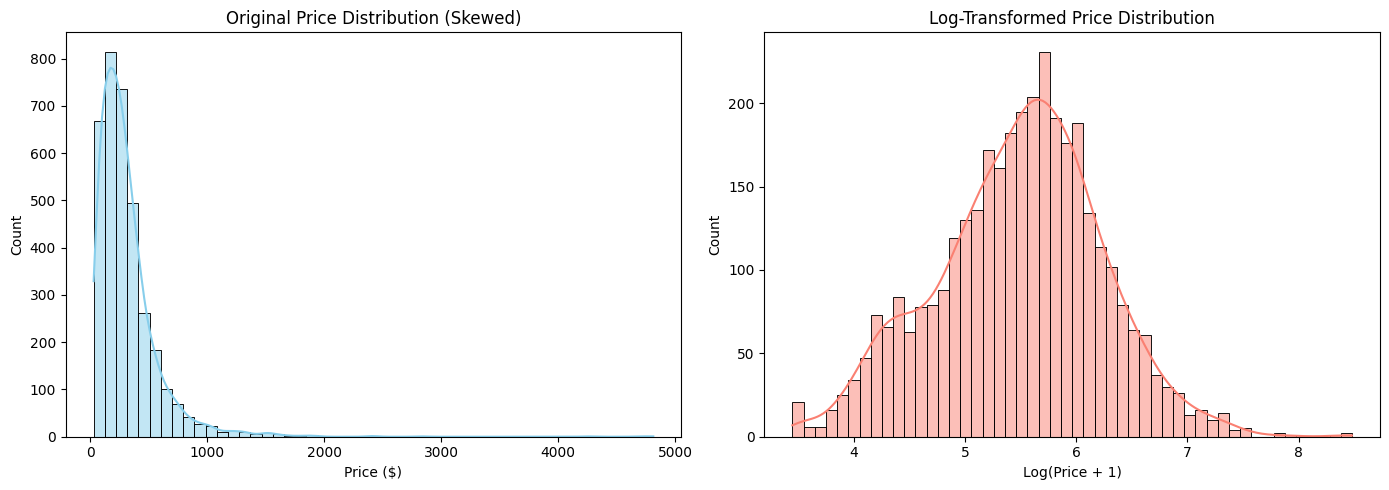

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)

price_data = df['price'].dropna()
price_data = price_data[price_data > 0]

log_price_data = np.log1p(price_data)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(price_data, bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Original Price Distribution (Skewed)')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Count')

sns.histplot(log_price_data, bins=50, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('Log(Price + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. The Price Column

2. I transformed the column into a log-transformation. Because the price column is so skewed to the right, the log-transformation brings it to a normal skew.

3. The transformation shows more of an average between the price ranges, it allows analysts to see new distribution to compare.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [9]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
# Ensure price is numeric and clean of NaNs
df['price'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)
# Fill missing values to perform scaling cleanly
df['price'] = df['price'].fillna(df['price'].median())
df['minimum_nights'] = df['minimum_nights'].fillna(df['minimum_nights'].median())

min_max_scaler = MinMaxScaler()
df['price_min_max'] = min_max_scaler.fit_transform(df[['price']])

# 2. Z-score scale 'minimum_nights'
standard_scaler = StandardScaler()
df['minimum_nights_zscore'] = standard_scaler.fit_transform(df[['minimum_nights']])
# Display summary statistics of the original and scaled columns
display(df[['price', 'price_min_max', 'minimum_nights', 'minimum_nights_zscore']].describe())

,price,price_min_max,minimum_nights,minimum_nights_zscore
count,4368.000000,4368.000000,4368.000000,4.368000e+03
mean,302.675245,0.056899,18.746337,5.205441e-17
std,251.056087,0.052472,28.401997,1.000114e+00
min,30.440000,0.000000,1.000000,-6.248986e-01
25%,175.000000,0.030214,1.000000,-6.248986e-01
50%,253.330000,0.046585,2.000000,-5.896858e-01
75%,349.127500,0.066607,29.000000,3.610604e-01
max,4815.000000,1.000000,400.000000,1.342502e+01



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. Price and Minimum_nights. They both have very different ranges. I used min/max for price and z-score for minimum_nights.

2. It gives a more accurate description.

3. Customers will be able to scale pricing compared to minimum_nights available.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [10]:
df['number_of_reviews'] = df['number_of_reviews'].fillna(0)

labels = ['Low', 'Medium', 'High']
df['review_volume'] = pd.qcut(df['number_of_reviews'], q=3, labels=labels, duplicates='drop')

if df['review_volume'].nunique() < 3:
    bins = [-1, 5, 30, df['number_of_reviews'].max()]
    df['review_volume'] = pd.cut(df['number_of_reviews'], bins=bins, labels=labels)

print("Value counts for the new 'review_volume' column:")
print(df['review_volume'].value_counts())

display(df[['number_of_reviews', 'review_volume']].head(15))

Value counts for the new 'review_volume' column:
review_volume
Low       1500
High      1454
Medium    1414
Name: count, dtype: int64


,number_of_reviews,review_volume
0,27,Medium
1,144,High
2,144,High
3,9,Medium
4,7,Medium
5,2,Low
6,51,High
7,109,High
8,146,High
9,344,High


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the number_of_reviews into Low, medium, and high categories.

2. It gives a better idea of how many lower reviews there are, medium reviews, and high reviews on the site.

3. This could help hosts to see their lower reviews and fix any issues pertaining to them, but also show customers how certain listings are reviewed by other customers.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [11]:
accommodates_clean = df['accommodates'].fillna(1).replace(0, 1)
df['price_per_accommodates'] = df['price'] / accommodates_clean

df['is_long_term_stay'] = df['minimum_nights'] >= 30

display(df[['price', 'accommodates', 'price_per_accommodates', 'minimum_nights', 'is_long_term_stay']].head(10))

,price,accommodates,price_per_accommodates,minimum_nights,is_long_term_stay
0,111.62,2,55.810000,29.0,False
1,189.00,2,94.500000,1.0,False
2,254.38,4,63.595000,2.0,False
3,134.62,3,44.873333,91.0,True
4,169.75,2,84.875000,32.0,True
5,148.20,2,74.100000,60.0,True
6,188.90,6,31.483333,29.0,False
7,154.40,2,77.200000,5.0,False
8,101.55,3,33.850000,29.0,False
9,138.00,2,69.000000,1.0,False


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. price_per_accommodates and is_long_term_stay.

2. Hosts can use this to add systems showing how much prices would be based on how many people are staying there. Platform can use the is_long_term_stay to create a separate area for customers to choose long term stays specifically.

3. Customers can decide which airbnb to choose based on how many people will be staying there. Is_long_term_stay can help customers find places to stay long-term.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1.
2.
3.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [14]:
# export csv here 🔧

Your dataset was successfully exported as 'cleaned_airbnb_data_7.csv'!


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. Step 5 seemed like the most important/helpful for customers and hosts alike. I would like to see columns like that when searching for listings.

2. Categorizing the reviews would be helpful for hosts to get a better idea of how their listings are being reviewed.

3. I would create charts and distribution charts to better analyze this data altogether.
4. This helps me better understand how to categorize certain columns in different ways. Using binary categorization is helpful to get more accurate data.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"